# Korpus aufbauen

In [211]:
import os

corpus = [] #initial empty list

os.getcwd() #get current path

data_folder = os.path.join(os.getcwd(), "korpus") #join current path with directory name
print(list(os.walk(data_folder))) #check files inside of chosen directory

for root, folders, files in os.walk(data_folder): #structure of list is root -> folders -> files
    for file in files:
        path = os.path.join(root, file)
        with open(path, encoding="utf8") as input: #encode in utf8 for special characters like ä.ü,ö,ß
            corpus.append(input.read()) #append every file as new list-item
input.close()

print(len(corpus),"Texte wurden erfolgreich in den Korpus geladen.")


[('c:\\workspace\\nlp-lernen\\korpus', [], ['aanrud-sidsel_langroeckchen.txt', 'achleitner-Im_gruenen_Tann.txt', 'achleitner-Unter_den_Hohen_Tauern.txt', 'alarcon-Der Dreispitz.txt', 'alberti-Japanische Märchen.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 40.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 42.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 56.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 63.txt', 'goethe-faust1.txt', 'goethe-faust2.txt', 'kafka-landarzt.txt', 'kafka-urteil.txt', 'kafka-verwandlung.txt', 'schiller-raeuber.txt', 'Skowronnek-Sturmzeichen.txt', 'westermann-Die Nutzpflanzen unserer Kolonien und ihre wirtschaftliche Bedeutung für das Mutterland.txt'])]
17 Texte wurden erfolgreich in den Korpus geladen.


In [228]:
import nltk
from nltk.text import Text
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.util import ngrams
from nltk.tokenize import word_tokenize
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
import numpy as np
import spacy
from textstat.textstat import textstatistics
import pyphen
import re

corpus_list = []
#corpus_vec = []
corpus_name = []

def number_words(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    return len(text_words)

def avg_word_len(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    avg_word_len = sum(len(word) for word in text_words) / len(text_words)
    return round(avg_word_len,1)

def number_sentences(text):
    sentences = nltk.sent_tokenize(text) #tokenize in sentences
    return len(sentences)

def avg_sen_len(text):
    avg_sen_len = round(number_words(text) / number_sentences(text),1) #average sentence length
    return avg_sen_len

#Type-Token-Ratio (TTR)
def ttr(tokens):
    return len(set(tokens)) / len(tokens) if tokens else 0 #make set without duplicates and divide with all tokens (incl. duplicates); if list is empty, dont divide with 0 just say, its 0

def punctuations(tokens):
    excl = 0
    quest = 0
    pct = 0
    com = 0
    semic = 0
    colo = 0

    for i in tokens:
        if i == "!":
            excl += 1
        if i == "?":
            quest += 1
        if i == ".":
            pct += 1
        if i == ",":
            com += 1
        if i == ";":
            semic += 1
        if i == ":":
            colo += 1

    erg_excl = excl / len(tokens)
    erg_quest = quest / len(tokens)
    erg_pct = pct / len(tokens)
    erg_com = com / len(tokens)
    erg_semic = semic / len(tokens)
    erg_colo = colo / len(tokens)

    return erg_excl, erg_quest, erg_pct, erg_com, erg_semic, erg_colo

def syllables_count(text, sprache='de_DE'):
    dic = pyphen.Pyphen(lang=sprache)
    worte = text.split()
    #print(worte)
    silben_gesamt = 0
    global syll1
    syll1 = 0
    
    for wort in worte:
        silben = dic.inserted(wort).split('-')
        #print(silben, len(silben))
        if len(silben) == 1:
            syll1 += 1
            #print("Silbe hier:",len(silben),"---->",silben)
        silben_gesamt += len(silben)

    return silben_gesamt

def avg_syllables_per_word(var3):
    #print("Übermittel var3:",var3)
    words = re.findall(r'\b\w+\b', var3.lower())
    avg_syllables = syllables_count(var3) / len(words)
    #print("Silben:",syllables_count(var3))
    #print("Wörter:",len(words))
    return round(avg_syllables, 1)

def flesch_reading_ease_ger(asl, asw):
    
    fre = 180 - asl - (58.5 - asw)
    
    return round(fre,2)

def wiener_sachtext_formel(text):
    syll = 0
    ms = 0 
    sl = 0
    iw = 0
    es = 0
    words6 = 0
    global syll1

    if syllables_count(text) > 3:
        syll += 1
    ms = syll / number_words(text) * 100
    sl = avg_sen_len(text)

    words = re.findall(r'\b\w+\b', text.lower())
    for word in words:
        if len(word) > 5:
            #print("hier:",len(word),"---->",word)
            words6 += 1
    iw = words6 / number_words(text)
    es = syll1 / number_words(text) * 100
    # print("MS:",ms)
    # print("SL:",sl)
    # print("SL:",sl)
    # print("IW:",iw)
    # print("ES:",es)

    # print("syll1:",syll1)
    # print("# Words:",number_words(text))
    #print("Formel: 0.1935 *", ms,"+ 0.1672 *", sl,"+ 0.1297 *", iw,"- 0.0327 *", es," - 0.875")

    wsf = 0.1935 * ms + 0.1672 * sl + 0.1297 * iw - 0.0327 * es - 0.875
    return round(wsf,2)

def ngram_haeufigkeit(text):
    # Kleinbuchstaben & Tokenisierung
    tokens = word_tokenize(text.lower())

    # Bigramme & Trigramme erzeugen
    bigramme = list(ngrams(tokens, 2))
    trigramme = list(ngrams(tokens, 3))

    # Häufigkeiten zählen
    bigram_haeufigkeit = Counter(bigramme)
    trigram_haeufigkeit = Counter(trigramme)

    # Ergebnisse anzeigen
    print(f"Anzahl eindeutiger Bigramme: {len(bigram_haeufigkeit)}")
    print(f"Anzahl eindeutiger Trigramme: {len(trigram_haeufigkeit)}\n")

    print("Top 5 Bigramme:")
    for bigram, count in bigram_haeufigkeit.most_common(5):
        print(f"{bigram} → {count} Mal")

    print("\nTop 5 Trigramme:")
    for trigram, count in trigram_haeufigkeit.most_common(5):
        print(f"{trigram} → {count} Mal")



In [215]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(analyzer='word', ngram_range=(1, 2), binary=True)
X = vectorizer.fit_transform(corpus)

In [216]:
dist_matrix = cosine_distances(X)

for i, text in enumerate(corpus):
    print(f"Vektor für Text {i} →",
          X[i].toarray().reshape(-1)[:37]) 

print("\nCosine-Distanz-Matrix:")
print(dist_matrix)

Vektor für Text 0 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 1 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 0 0]
Vektor für Text 2 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0]
Vektor für Text 3 → [0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 4 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 5 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]
Vektor für Text 6 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0]
Vektor für Text 7 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]
Vektor für Text 8 → [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]
Vektor für Text 9 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 10 → [0 0 0 0 0 0 0 0 0 

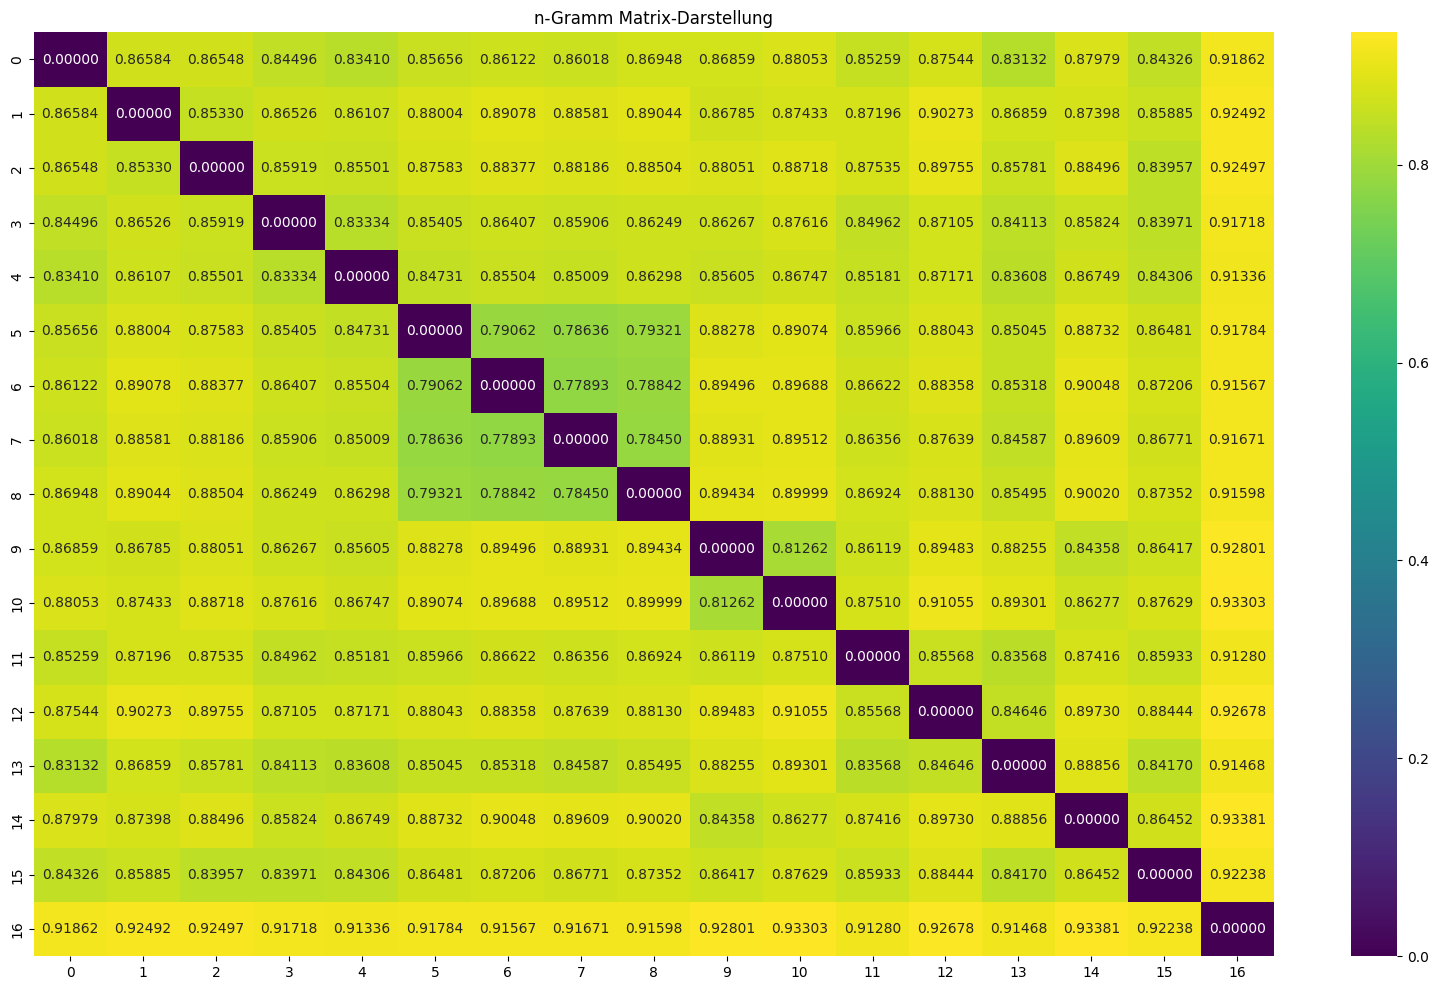

In [217]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(dist_matrix)

plt.figure(figsize=(20, 12))
sns.heatmap(df, annot=True, fmt=".5f", cmap="viridis")
plt.title("n-Gramm Matrix-Darstellung")
plt.show()


In [229]:
for text in corpus:

    nltk_text = Text(nltk.word_tokenize(text.lower())) #lower, damit es keine Doppelungen beim zählen später gibt
    #nltk_text_words = word_tokenize(text)
    
    wordcount = number_words(text)
    sentencescount = number_sentences(text)
    print(wordcount,sentencescount)

    avgsenlen = avg_sen_len(text) #average sentence length
    #print(avg_sen_len)
    avgwordlen = avg_word_len(text)
    #print(avg_word_len)
    #print(avgwordlen,avgsenlen)


    ttr_erg = round(ttr(nltk_text),2)
    avg_punct = punctuations(nltk_text)
    
    avg_syll = avg_syllables_per_word(text)
    fre_ger = flesch_reading_ease_ger(avgsenlen, avg_syll)
    wsf = wiener_sachtext_formel(text)
    print(avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg)
    print(ngram_haeufigkeit(text))

    corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, fre_ger, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[2],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3)]) #All Features
    #corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg])
    corpus_name.append(nltk_text)

    print("-----------------------------------------------")

#print("Corpuslist:",corpus_list)

27616 1213
4.8 22.8 1.6 1.11 0.14
Anzahl eindeutiger Bigramme: 18890
Anzahl eindeutiger Trigramme: 28929

Top 5 Bigramme:
(',', 'und') → 336 Mal
(',', 'daß') → 194 Mal
(',', 'die') → 161 Mal
(',', 'als') → 107 Mal
(',', 'das') → 88 Mal

Top 5 Trigramme:
(',', 'daß', 'sie') → 68 Mal
('*', '*', '*') → 56 Mal
(',', 'als', 'sie') → 27 Mal
('.', 'ja', ',') → 24 Mal
(',', 'daß', 'er') → 22 Mal
None
-----------------------------------------------
54302 2749
5.3 19.8 1.7 0.72 0.17
Anzahl eindeutiger Bigramme: 41596
Anzahl eindeutiger Trigramme: 59601

Top 5 Bigramme:
('!', '“') → 433 Mal
(',', 'und') → 342 Mal
('“', '„') → 292 Mal
(',', 'die') → 257 Mal
(',', 'daß') → 220 Mal

Top 5 Trigramme:
('!', '“', '„') → 186 Mal
('*', '*', '*') → 132 Mal
('?', '“', '„') → 80 Mal
('.', '*', '*') → 38 Mal
(',', 'daß', 'die') → 34 Mal
None
-----------------------------------------------
63931 4079
5.5 15.7 1.8 0.18 0.15
Anzahl eindeutiger Bigramme: 46688
Anzahl eindeutiger Trigramme: 69058

Top 5 Bigramme:

In [230]:
corpus_list

[[4.8, 22.8, 1.6, 1.11, 100.3, 0.14, 0.003, 0.002, 0.033, 0.082, 0.011, 0.003],
 [5.3, 19.8, 1.7, 0.72, 103.4, 0.17, 0.017, 0.004, 0.03, 0.066, 0.004, 0.004],
 [5.5, 15.7, 1.8, 0.18, 107.6, 0.15, 0.032, 0.005, 0.029, 0.062, 0.002, 0.005],
 [5.0, 20.4, 1.7, 0.8, 102.8, 0.17, 0.01, 0.007, 0.029, 0.087, 0.002, 0.002],
 [4.9, 24.2, 1.6, 1.45, 98.9, 0.16, 0.007, 0.002, 0.032, 0.07, 0.006, 0.005],
 [5.4, 15.8, 1.8, 0.16, 107.5, 0.2, 0.001, 0.003, 0.051, 0.073, 0.0, 0.0],
 [5.5, 16.4, 1.8, 0.29, 106.9, 0.2, 0.001, 0.002, 0.049, 0.074, 0.0, 0.0],
 [5.4, 16.4, 1.8, 0.3, 106.9, 0.21, 0.001, 0.001, 0.051, 0.072, 0.0, 0.0],
 [5.5, 15.1, 1.8, 0.07, 108.2, 0.21, 0.001, 0.001, 0.054, 0.073, 0.0, 0.0],
 [4.8, 8.1, 1.5, -1.51, 114.9, 0.16, 0.03, 0.011, 0.059, 0.072, 0.008, 0.001],
 [5.1,
  13.6,
  1.7,
  -0.39,
  109.6,
  0.18,
  0.018,
  0.007,
  0.035,
  0.091,
  0.013,
  0.022],
 [5.1, 21.7, 1.7, 0.98, 101.5, 0.23, 0.002, 0.002, 0.036, 0.079, 0.021, 0.003],
 [5.0, 20.5, 1.7, 0.74, 102.7, 0.27, 0.007

In [231]:
corpus_vec = np.array(corpus_list)
corpus_matrix = cosine_distances(corpus_vec)

In [232]:
corpus_matrix = cosine_distances(corpus_vec)
corpus_matrix

array([[0.00000000e+00, 6.02068173e-04, 3.13138284e-03, 3.86240541e-04,
        1.42081338e-04, 3.04902401e-03, 2.57561763e-03, 2.57161671e-03,
        3.64748270e-03, 1.19767154e-02, 5.09236681e-03, 8.76014185e-05,
        3.58644604e-04, 3.10153534e-03, 7.92840696e-03, 2.13083942e-03,
        5.84623162e-03],
       [6.02068173e-04, 0.00000000e+00, 9.92322693e-04, 2.61757602e-05,
        1.31515393e-03, 9.47972818e-04, 6.90346509e-04, 6.89981150e-04,
        1.29247466e-03, 7.27423189e-03, 2.21719716e-03, 2.33171091e-04,
        3.43804573e-05, 6.38546658e-03, 4.20431646e-03, 4.75598705e-04,
        2.70824812e-03],
       [3.13138284e-03, 9.92322693e-04, 0.00000000e+00, 1.31927548e-03,
        4.58721679e-03, 1.11947301e-06, 2.75977235e-05, 2.79196388e-05,
        2.01000631e-05, 2.92217038e-03, 2.52865156e-04, 2.18536242e-03,
        1.37433857e-03, 1.23916244e-02, 1.12902911e-03, 9.84661510e-05,
        4.23077972e-04],
       [3.86240541e-04, 2.61757602e-05, 1.31927548e-03, 0.000

# Heatmap zeichnen

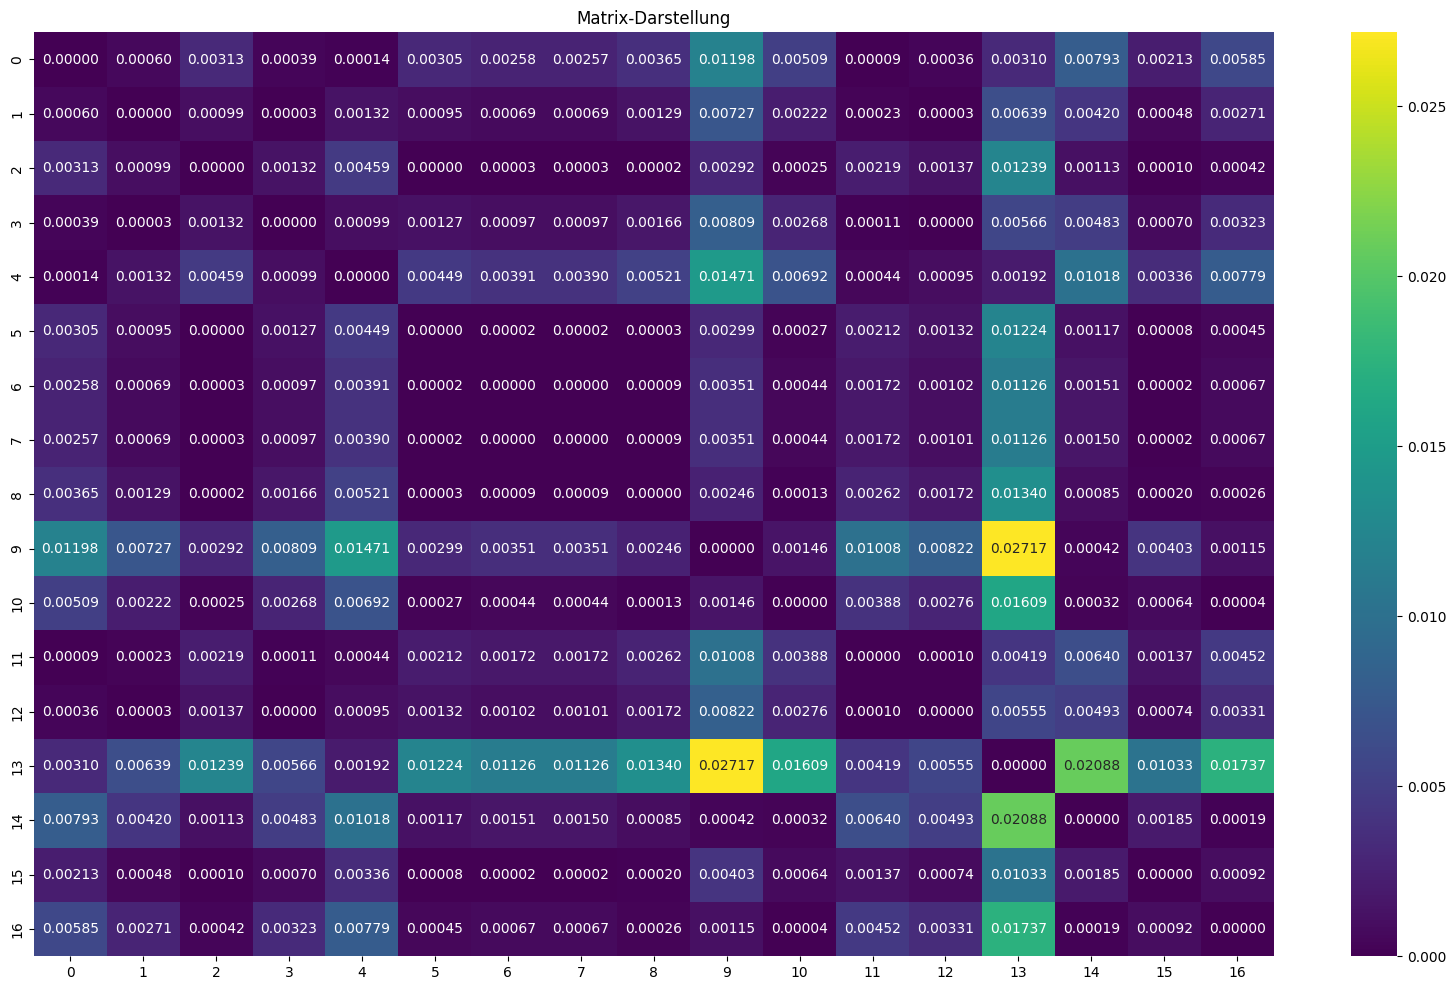

In [233]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(corpus_matrix)

plt.figure(figsize=(20, 12))
sns.heatmap(df, annot=True, fmt=".5f", cmap="viridis")
plt.title("Matrix-Darstellung")
plt.show()


-----------------------------------------------------------------

# Decision Tree

In [ ]:
avgwordlen, avgsenlen, avg_syll, wsf, fre_ger, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[2],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3)]

In [235]:
colu = ['AverageWordLength', 'AverageSentenceLength', 'AverageSyllables', 'WienerSachtextFormel', 'FRE_Ger', 'TTR', 'Avg !', 'Avg ?', 'Avg .', 'Avg ,', 'Avg ;', 'Avg :']
corp = pd.DataFrame(corpus_list)
corp.columns = colu
corp

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :
0,4.8,22.8,1.6,1.11,100.3,0.14,0.003,0.002,0.033,0.082,0.011,0.003
1,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004
2,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005
3,5.0,20.4,1.7,0.80,102.8,0.17,0.010,0.007,0.029,0.087,0.002,0.002
4,4.9,24.2,1.6,1.45,98.9,0.16,0.007,0.002,0.032,0.070,0.006,0.005
5,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000
6,5.5,16.4,1.8,0.29,106.9,0.20,0.001,0.002,0.049,0.074,0.000,0.000
7,5.4,16.4,1.8,0.30,106.9,0.21,0.001,0.001,0.051,0.072,0.000,0.000
8,5.5,15.1,1.8,0.07,108.2,0.21,0.001,0.001,0.054,0.073,0.000,0.000
9,4.8,8.1,1.5,-1.51,114.9,0.16,0.030,0.011,0.059,0.072,0.008,0.001


In [236]:
corp["Author"]= ["aanrud", "achleitner", "achleitner", "alarcon", "alberti", "anonymous", "anonymous", "anonymous", "anonymous", "goethe", "goethe", "kafka", "kafka", "kafka", "schuller", "skowronnek", "westermann"]
corp

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :,Author
0,4.8,22.8,1.6,1.11,100.3,0.14,0.003,0.002,0.033,0.082,0.011,0.003,aanrud
1,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004,achleitner
2,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005,achleitner
3,5.0,20.4,1.7,0.80,102.8,0.17,0.010,0.007,0.029,0.087,0.002,0.002,alarcon
4,4.9,24.2,1.6,1.45,98.9,0.16,0.007,0.002,0.032,0.070,0.006,0.005,alberti
5,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000,anonymous
6,5.5,16.4,1.8,0.29,106.9,0.20,0.001,0.002,0.049,0.074,0.000,0.000,anonymous
7,5.4,16.4,1.8,0.30,106.9,0.21,0.001,0.001,0.051,0.072,0.000,0.000,anonymous
8,5.5,15.1,1.8,0.07,108.2,0.21,0.001,0.001,0.054,0.073,0.000,0.000,anonymous
9,4.8,8.1,1.5,-1.51,114.9,0.16,0.030,0.011,0.059,0.072,0.008,0.001,goethe


In [237]:
X = corp[colu] # Features
y = corp.Author # Target variable

In [238]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1) # 70% training and 30% test


In [239]:
# Create Decision Tree classifer object
clf = DecisionTreeClassifier()

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)


In [240]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))


Accuracy: 0.5


In [358]:
X = corp.iloc[:,0:12]
X

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :
0,4.8,22.8,1.6,1.11,100.3,0.14,0.003,0.002,0.033,0.082,0.011,0.003
1,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004
2,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005
3,5.0,20.4,1.7,0.80,102.8,0.17,0.010,0.007,0.029,0.087,0.002,0.002
4,4.9,24.2,1.6,1.45,98.9,0.16,0.007,0.002,0.032,0.070,0.006,0.005
5,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000
6,5.5,16.4,1.8,0.29,106.9,0.20,0.001,0.002,0.049,0.074,0.000,0.000
7,5.4,16.4,1.8,0.30,106.9,0.21,0.001,0.001,0.051,0.072,0.000,0.000
8,5.5,15.1,1.8,0.07,108.2,0.21,0.001,0.001,0.054,0.073,0.000,0.000
9,4.8,8.1,1.5,-1.51,114.9,0.16,0.030,0.011,0.059,0.072,0.008,0.001


In [359]:
y = corp.iloc[:,12]
y

0         aanrud
1     achleitner
2     achleitner
3        alarcon
4        alberti
5      anonymous
6      anonymous
7      anonymous
8      anonymous
9         goethe
10        goethe
11         kafka
12         kafka
13         kafka
14      schuller
15    skowronnek
16    westermann
Name: Author, dtype: object

In [243]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=10, test_size=0.2)

In [244]:
X_train.shape

(13, 12)

In [245]:
X_test.shape

(4, 12)

In [246]:
y_train.shape

(13,)

In [247]:
y_test.shape

(4,)

In [248]:
from sklearn.tree import DecisionTreeClassifier
dtc = DecisionTreeClassifier()

In [249]:
dtc.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': None,
 'splitter': 'best'}

In [250]:
dtc.fit(X_train, y_train)

DecisionTreeClassifier()

In [251]:
y_pred = dtc.predict(X_test)

In [252]:
from sklearn.metrics import confusion_matrix, classification_report
print(confusion_matrix(y_test, y_pred))

[[0 0 0 1 0]
 [0 2 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 1 0 0]]


In [253]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     alarcon       0.00      0.00      0.00         1
   anonymous       1.00      1.00      1.00         2
      goethe       0.00      0.00      0.00         0
       kafka       0.00      0.00      0.00         0
    schuller       0.00      0.00      0.00         1

    accuracy                           0.50         4
   macro avg       0.20      0.20      0.20         4
weighted avg       0.50      0.50      0.50         4



c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-l

In [254]:
dtc.feature_importances_

array([0.17303241, 0.18298611, 0.        , 0.09027778, 0.        ,
       0.1625    , 0.13541667, 0.        , 0.09027778, 0.16550926,
       0.        , 0.        ])

In [255]:
X.columns

Index(['AverageWordLength', 'AverageSentenceLength', 'AverageSyllables',
       'WienerSachtextFormel', 'FRE_Ger', 'TTR', 'Avg !', 'Avg ?', 'Avg .',
       'Avg ,', 'Avg ;', 'Avg :'],
      dtype='object')

In [256]:
features = pd.DataFrame(dtc.feature_importances_, index=X.columns)
features

,0
AverageWordLength,0.173032
AverageSentenceLength,0.182986
AverageSyllables,0.000000
WienerSachtextFormel,0.090278
FRE_Ger,0.000000
TTR,0.162500
Avg !,0.135417
Avg ?,0.000000
Avg .,0.090278
"Avg ,",0.165509


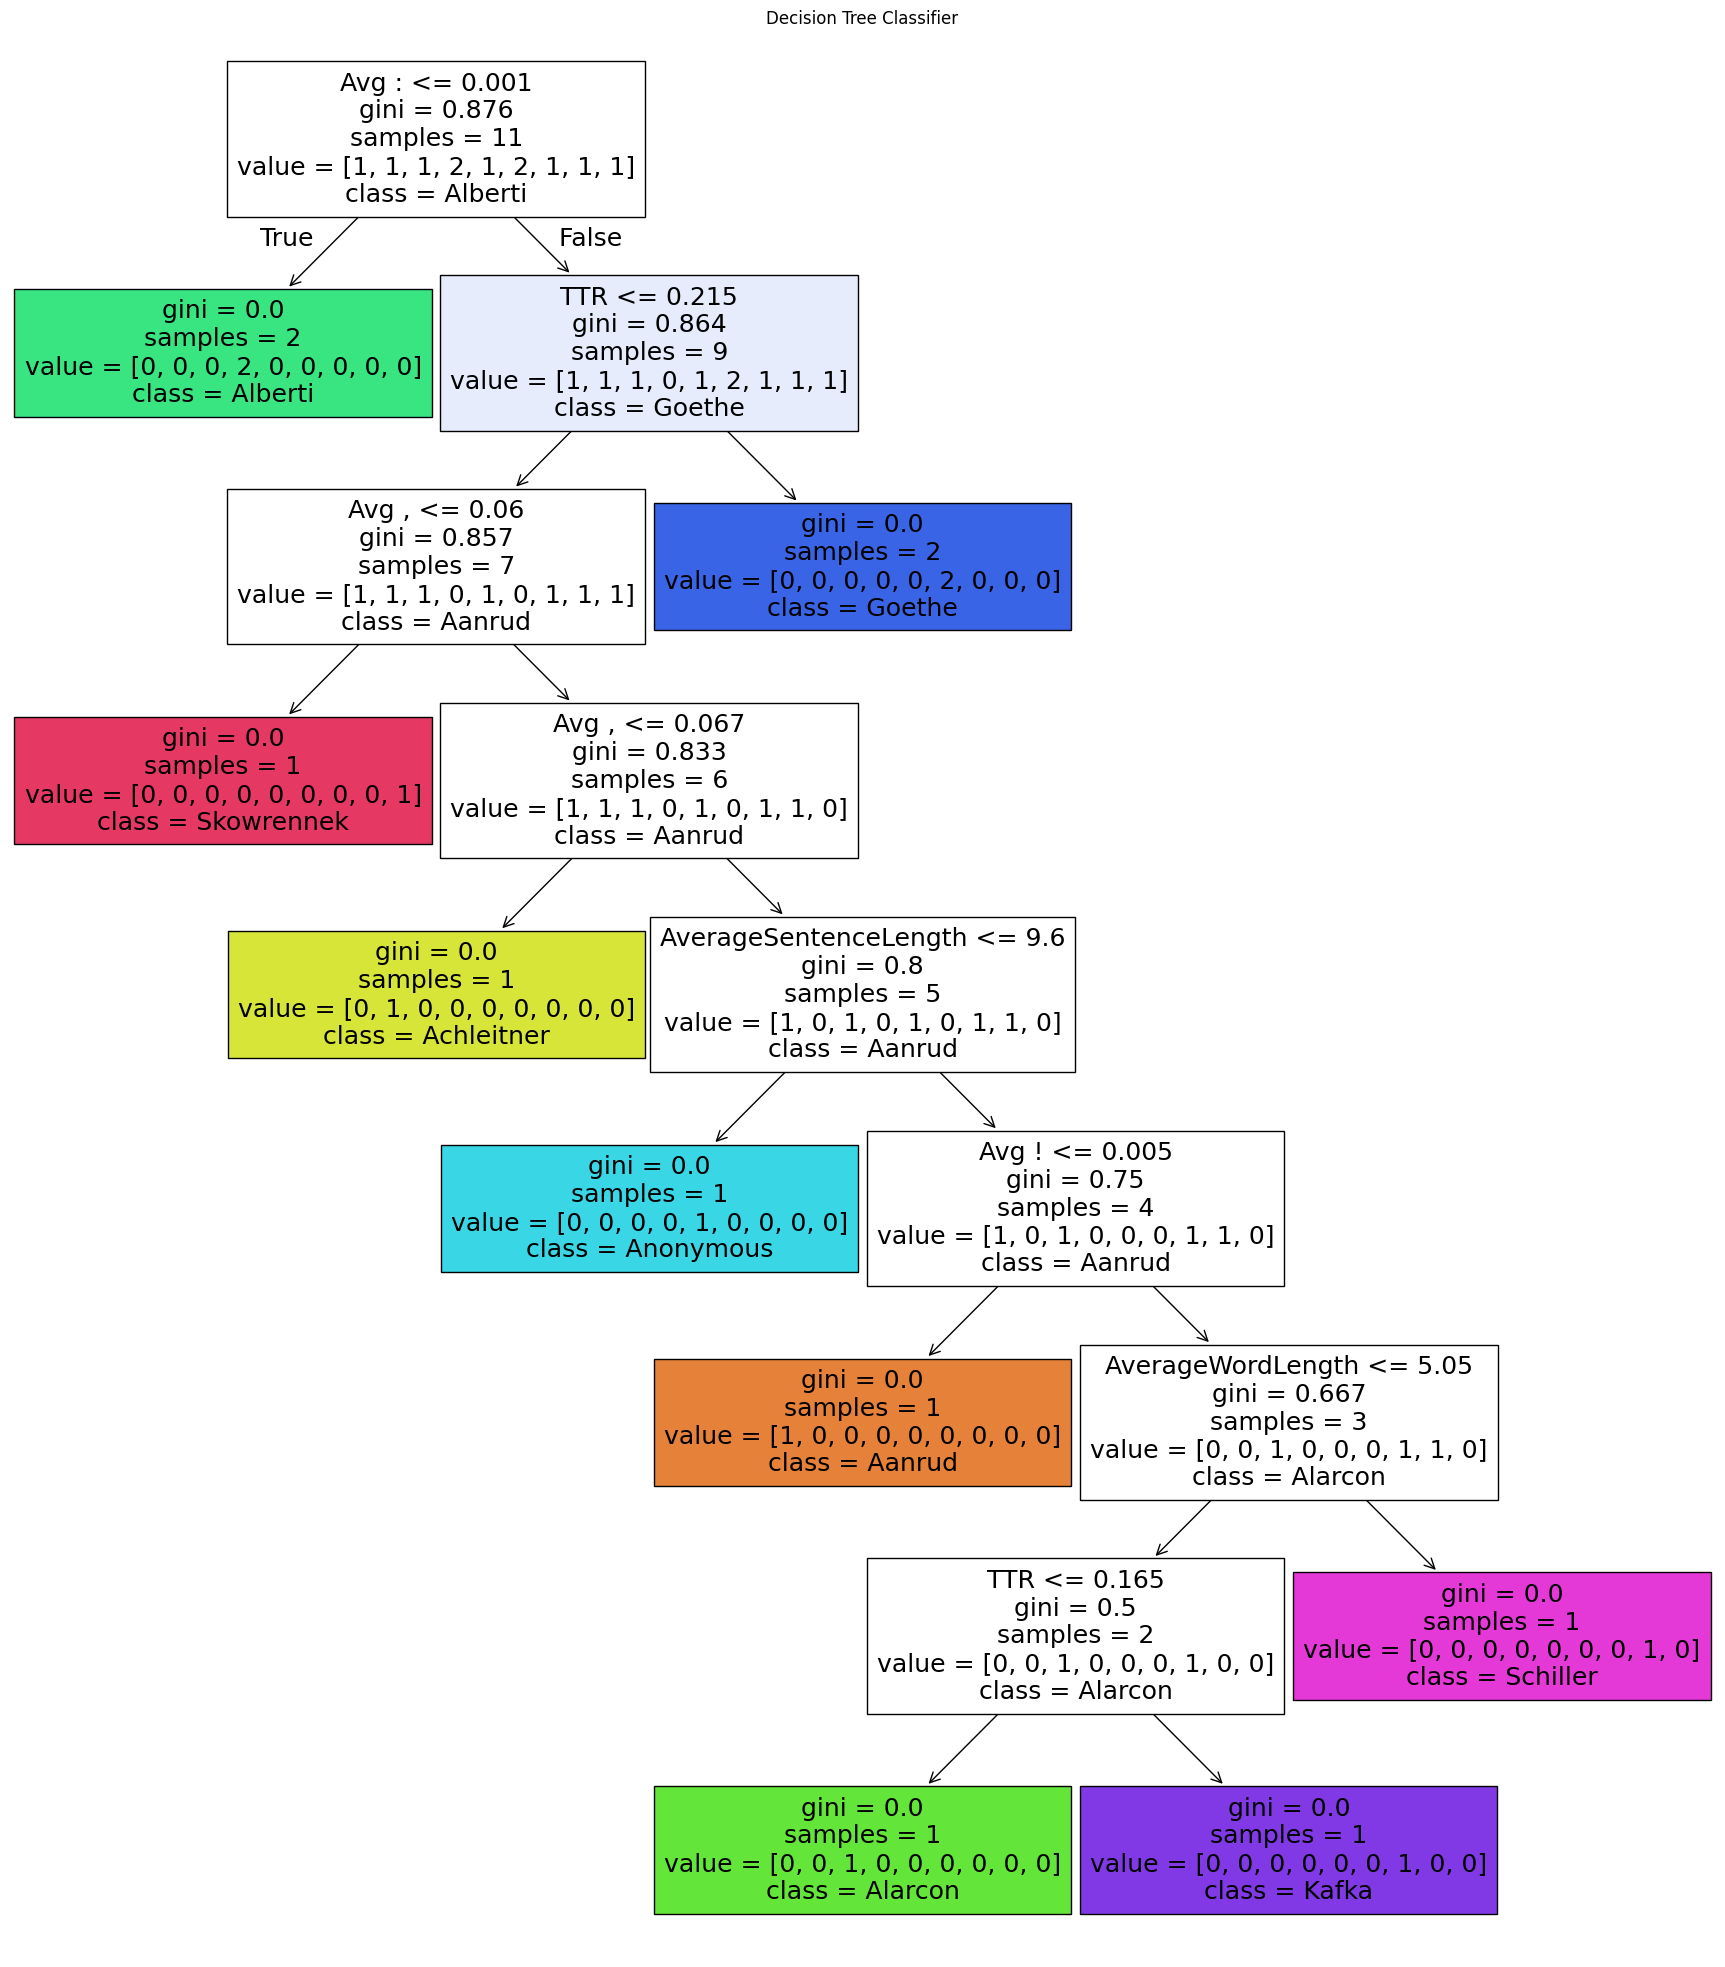

In [264]:
plt.figure(figsize=(22, 25))
tree.plot_tree(clf, filled=True, feature_names=X.columns, class_names=['Aanrud', 'Achleitner', 'Alarcon', 'Alberti', 'Anonymous', 'Goethe', 'Kafka', 'Schiller', 'Skowrennek', 'Westermann'])
plt.title("Decision Tree Classifier")
plt.show()


_______________________

# Random Forest

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [345]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

classifier = RandomForestClassifier(n_estimators=1000, random_state=42)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

y_pred

array(['kafka', 'alarcon', 'anonymous', 'anonymous'], dtype=object)

In [350]:
y_test

0         aanrud
1     achleitner
5      anonymous
15    skowronnek
Name: Author, dtype: object

In [279]:
class_names=['Aanrud', 'Achleitner', 'Alarcon', 'Alberti', 'Anonymous', 'Goethe', 'Kafka', 'Schiller', 'Skowrennek', 'Westermann']

Accuracy: 25.00%


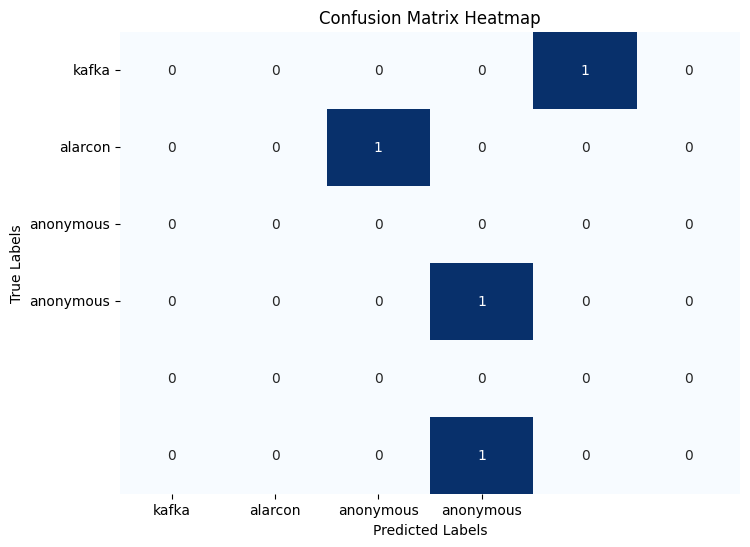

In [351]:
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False, 
            xticklabels=y_pred, yticklabels=y_pred)

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [337]:
conf_matrix

array([[0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 1, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 0, 0],
       [0, 0, 1, 0, 0, 0, 0]])

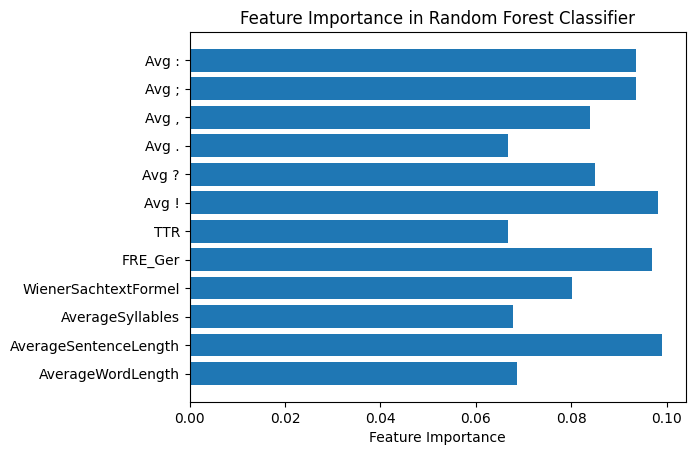

In [347]:
feature_importances = classifier.feature_importances_

plt.barh(X.columns, feature_importances)
plt.xlabel('Feature Importance')
plt.title('Feature Importance in Random Forest Classifier')
plt.show()

In [349]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      aanrud       0.00      0.00      0.00         1
  achleitner       0.00      0.00      0.00         1
     alarcon       0.00      0.00      0.00         0
   anonymous       0.50      1.00      0.67         1
       kafka       0.00      0.00      0.00         0
  skowronnek       0.00      0.00      0.00         1

    accuracy                           0.25         4
   macro avg       0.08      0.17      0.11         4
weighted avg       0.12      0.25      0.17         4



c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-l

________________________

# Support Vector Machine

In [366]:
# Load the important packages
from sklearn.datasets import load_breast_cancer
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.svm import SVC


In [367]:
#Build the model
svm = SVC(kernel="rbf", gamma=0.5, C=1.0)
# Trained the model
svm.fit(X, y)

# Plot Decision Boundary
DecisionBoundaryDisplay.from_estimator(
        svm,
        X,
        response_method="predict",
        cmap=plt.cm.Spectral,
        alpha=0.8,
        xlabel=X.columns,
        ylabel=class_names,
    )

# Scatter plot
plt.scatter(X[:, 0], X[:, 1], 
            c=y, 
            s=20, edgecolors="k")
plt.show()

ValueError: n_features must be equal to 2. Got 12 instead.